# k-Nearest Neighbors

In [1]:
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, OneHotEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.pipeline import make_pipeline
warnings.filterwarnings("ignore", category=FutureWarning)
username = "ritama.sanyal"
seed = int(hashlib.sha256(username.encode()).hexdigest(), 16) % (2**32)
print(f"Using seed: {seed}")

Using seed: 284869898


### HELPER CLASS FOR FEAUTURE TRANSFORMATION

In [2]:
class PerFeatureTransformer:
    def __init__(self):
        """Initializes memory for per-feature transformers."""
        self.transformers = {}

    def fit(self, df: pd.DataFrame, params: dict[str, str]) -> None:
        """
        Fits transformers for each feature based on the given type.

        Parameters:
            df: The dataframe containing features to be transformed.
            params: A dictionary mapping feature name to transformation type,
                    e.g., {"GPA": "standard", "major": "ordinal", "program": "onehot"}.
        """
        for feature, transform_type in params.items():
            if transform_type == 'standard':
                transformer = StandardScaler()
                # Reshape data for single feature
                transformer.fit(df[[feature]].values)
            elif transform_type == 'ordinal':
                transformer = OrdinalEncoder()
                transformer.fit(df[[feature]].values)
            elif transform_type == 'onehot':
                transformer = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
                transformer.fit(df[[feature]].values)
            else:
                raise ValueError(f"Unknown transformation type: {transform_type}")
            
            self.transformers[feature] = transformer

    def transform(self, df: pd.DataFrame) -> np.ndarray:
        """
        Applies the fitted transformers to the corresponding features 
        and returns a NumPy array.
        """
        transformed_features = []
        for feature, transformer in self.transformers.items():
            transformed_data = transformer.transform(df[[feature]].values)
            transformed_features.append(transformed_data)
        
        # Combine all transformed features into a single matrix
        return np.hstack(transformed_features)

    def fit_transform(self, df: pd.DataFrame, params: dict[str, str]) -> np.ndarray:
        """
        Fits and transforms all features in one step using the
        given transformation parameters.
        """
        self.fit(df, params)
        return self.transform(df)

###  KNNGenderPredictor Class Implementation

In [3]:
class KNNGenderPredictor:
    def __init__(self, student_df_path: str, username: str, seed: int):
        """
        Initializes the predictor with the full student dataset.
        Use the username for plots.
        """
        self.df = pd.read_csv(student_df_path)
        self.username = username
        self.seed = seed
        self.transformer = PerFeatureTransformer()
        
        # Define features and target (use correct case from CSV)
        self.features = ['gpa', 'major', 'program']
        self.target = 'gender'
        
        # Split data upon initialization
        self.X_train, self.X_val, self.X_test, self.y_train, self.y_val, self.y_test = self.train_val_test_split()

    def train_val_test_split(self, test_size: float = 0.2, val_size: float = 0.2) -> tuple:
        """Splits the data into training, validation, and testing sets."""
        X = self.df[self.features]
        y = self.df[self.target]
        
        # First split to separate out the test set
        X_train_val, X_test, y_train_val, y_test = train_test_split(
            X, y, test_size=test_size, random_state=self.seed, stratify=y
        )
        
        # Calculate the proportion of the validation set relative to the train_val set
        val_prop = val_size / (1 - test_size)
        
        # Second split to separate training and validation sets
        X_train, X_val, y_train, y_val = train_test_split(
            X_train_val, y_train_val, test_size=val_prop, random_state=self.seed, stratify=y_train_val
        )
        
        print(f"Training set size: {X_train.shape[0]}")
        print(f"Validation set size: {X_val.shape[0]}")
        print(f"Test set size: {X_test.shape[0]}")
        
        return X_train, X_val, X_test, y_train, y_val, y_test

    def get_feature_matrix_and_labels(self, X: pd.DataFrame, y: pd.Series) -> tuple[np.ndarray, np.ndarray]:
        """
        Extracts transformed features and labels from a DataFrame and label array.
        This method uses the single transformer that was fitted on the training data.
        """
        # Get the numerical feature matrix using the fitted transformer
        X_transformed = self.transformer.transform(X[self.features])
        
        # Get the corresponding labels
        y_labels = y.values
        
        return X_transformed, y_labels

    # --- Methods for finding the best k ---

    def get_knn_accuracy_vs_k(self, X_train_transformed, y_train, X_val_transformed, y_val, k_values: list[int], distance: str = "euclidean") -> list[float]:
        """Calculates accuracy scores for various k values on the validation set."""
        accuracy_scores = []
        for k in k_values:
            knn = KNeighborsClassifier(n_neighbors=k, metric=distance)
            # Fit the model on the TRANSFORMED training data
            knn.fit(X_train_transformed, y_train)
            # Predict on the TRANSFORMED validation data
            y_pred_val = knn.predict(X_val_transformed)
            accuracy = accuracy_score(y_val, y_pred_val)
            accuracy_scores.append(accuracy)
        return accuracy_scores

    def plot_knn_accuracy_vs_k(self, k_values: list[int], accuracy_scores: list[float], distance: str = "euclidean") -> None:
        """Plots accuracy scores against k values on the validation set."""
        # Find the best k
        best_k_index = np.argmax(accuracy_scores)
        best_k = k_values[best_k_index]
        max_accuracy = accuracy_scores[best_k_index]

        # Create the plot
        plt.figure(figsize=(12, 7))
        plt.plot(k_values, accuracy_scores, marker='o', linestyle='--')
        plt.text(0.95, 0.95, "ritama.sanyal",
            ha='right', va='top',
            transform=plt.gca().transAxes,
            fontsize=10, color='gray', alpha=0.7
        )

        # Highlight the best point
        plt.scatter(best_k, max_accuracy, color='red', s=150, zorder=5, label=f'Best k={best_k} (Acc: {max_accuracy:.4f})')
        plt.axvline(x=best_k, color='red', linestyle=':', linewidth=2)
        plt.title(f'k vs. Validation Accuracy (Distance: {distance.capitalize()}) - {self.username}')
        plt.xlabel("k (Number of Neighbors)")
        plt.ylabel("Validation Accuracy")
        plt.xticks(k_values)
        plt.legend()
        plt.grid(True)
        plt.show()

    def get_knn_f1_heatmap(self, X_train_transformed, y_train, X_val_transformed, y_val, k_values: list[int], distances: list[str]) -> pd.DataFrame:
        f1_scores_df = pd.DataFrame(index=k_values, columns=distances)
        f1_scores_df.index.name = 'k'
        for distance in distances:
            for k in k_values:
                knn = KNeighborsClassifier(n_neighbors=k, metric=distance)
                knn.fit(X_train_transformed, y_train)
                y_pred_val = knn.predict(X_val_transformed)
                f1 = f1_score(y_val, y_pred_val, average='weighted')
                f1_scores_df.loc[k, distance] = f1
        return f1_scores_df.astype(float) 

    def plot_knn_f1_heatmap(self, f1_scores_df: pd.DataFrame) -> None:
        plt.figure(figsize=(10, 8))
        sns.heatmap(
            f1_scores_df,
            annot=True,
            fmt=".4f",
            cmap="viridis",
            linewidths=.5
        )
        plt.title(f'F1-Score Heatmap: k vs. Distance Metric')
        plt.text(0.95, 0.95, "ritama.sanyal",
            ha='right', va='top',
            transform=plt.gca().transAxes,
            fontsize=10, color='gray', alpha=0.7
        )
        plt.xlabel("Distance Metric")
        plt.ylabel("k (Number of Neighbors)")
        plt.show()

    def get_knn_f1_single_feature_table(self, k_values: list[int], features: list[str], distances: list[str]) -> dict:
        """
        Creates a table of F1 scores on the test set using only a single feature for prediction.
        Returns a dictionary of DataFrames, one for each distance metric.
        """
        # Normalize feature names to lower case for matching
        features = [f.lower() for f in features]
        valid_features = ['gpa', 'major', 'program']
        results_by_distance = {}
        for distance in distances:
            f1_scores_df = pd.DataFrame(index=k_values, columns=features)
            f1_scores_df.index.name = 'k'
            for feature in features:
                if feature not in valid_features:
                    print(f"Warning: Feature '{feature}' not found in dataset. Skipping.")
                    continue
                single_feature_transformer = PerFeatureTransformer()
                if feature == 'gpa':
                    param_type = 'standard'
                elif feature == 'major':
                    param_type = 'ordinal'
                else: # program
                    param_type = 'onehot'
                single_feature_transformer.fit(self.X_train[[feature]], {feature: param_type})
                X_train_single = single_feature_transformer.transform(self.X_train[[feature]])
                X_test_single = single_feature_transformer.transform(self.X_test[[feature]])
                for k in k_values:
                    knn = KNeighborsClassifier(n_neighbors=k, metric=distance)
                    knn.fit(X_train_single, self.y_train)
                    y_pred_test = knn.predict(X_test_single)
                    f1 = f1_score(self.y_test, y_pred_test, average='weighted')
                    f1_scores_df.loc[k, feature] = f1
            results_by_distance[distance] = f1_scores_df.astype(float)
        return results_by_distance

### Instantiate Predictor and Prepare Data

In [4]:
# Instantiate the predictor
predictor = KNNGenderPredictor(student_df_path='student_dataset.csv', username=username, seed=seed)

# Define the transformation parameters
transform_params = {
    'gpa': 'standard',
    'major': 'ordinal', 
    'program': 'onehot'  
}

# --- Fit the transformer ONCE on the training data ---
print("\nFitting the transformer on the training data...")
predictor.transformer.fit(predictor.X_train, transform_params)
print("Transformer fitted.")

# --- Use the fitted transformer to prepare all data sets ---
X_train_transformed, y_train_labels = predictor.get_feature_matrix_and_labels(predictor.X_train, predictor.y_train)
X_val_transformed, y_val_labels = predictor.get_feature_matrix_and_labels(predictor.X_val, predictor.y_val)
X_test_transformed, y_test_labels = predictor.get_feature_matrix_and_labels(predictor.X_test, predictor.y_test)

print(f"\nShape of transformed training data: {X_train_transformed.shape}")

Training set size: 6000
Validation set size: 2000
Test set size: 2000

Fitting the transformer on the training data...
Transformer fitted.

Shape of transformed training data: (6000, 6)


What value of k (odd values from 1 to 21) gave the highest accuracy on the validation
 set with Euclidean distance metric? Justify with a plot

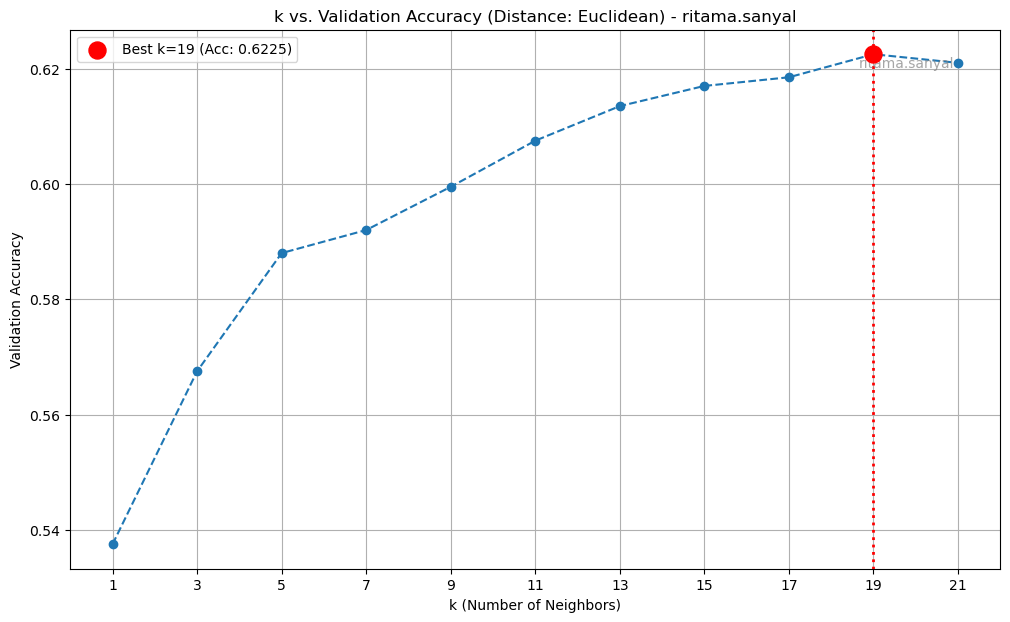

The value of k that gave the highest accuracy on the validation set is k = 19 with an accuracy of 0.6225.


In [5]:
# Define the odd k values from 1 to 21
k_values = range(1, 22, 2)

# Call the method with the TRANSFORMED data variables
accuracy_scores = predictor.get_knn_accuracy_vs_k(
    X_train_transformed, y_train_labels,
    X_val_transformed, y_val_labels,
    k_values,
    distance='euclidean'
)

# The plotting function remains the same
predictor.plot_knn_accuracy_vs_k(k_values, accuracy_scores, distance='euclidean')

# Print the best k value
best_k_index = np.argmax(accuracy_scores)
best_k = k_values[best_k_index]
max_accuracy = accuracy_scores[best_k_index]

print(f"The value of k that gave the highest accuracy on the validation set is k = {best_k} with an accuracy of {max_accuracy:.4f}.")

Repeat the above for distance metrics like Manhattan and Cosine Similarity.

--- Running experiment for Manhattan Distance ---


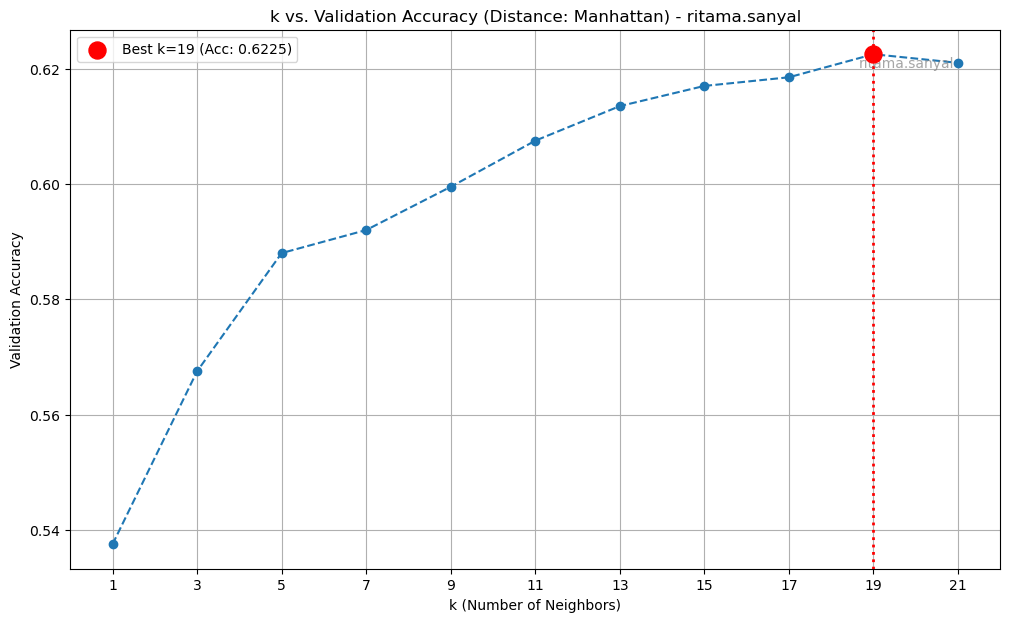

For Manhattan distance, the best k is 19 with an accuracy of 0.6225.

--- Running experiment for Cosine Distance ---


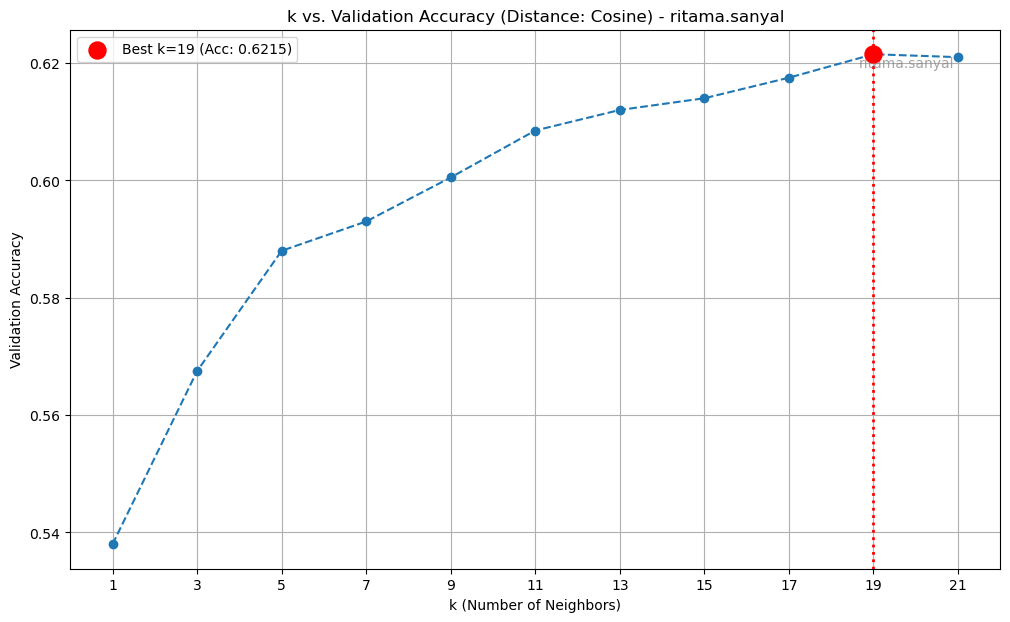

For Cosine distance, the best k is 19 with an accuracy of 0.6215.



In [6]:
# Define the k values and the distances to test
k_values = range(1, 22, 2)
distances_to_test = ['manhattan', 'cosine']

# Loop through each distance metric
for distance in distances_to_test:
    print(f"--- Running experiment for {distance.capitalize()} Distance ---")
    
    # Calculate the accuracy for each k using the current distance metric
    accuracy_scores = predictor.get_knn_accuracy_vs_k(
        X_train_transformed, y_train_labels,
        X_val_transformed, y_val_labels,
        k_values,
        distance=distance
    )

    # Plot the results
    predictor.plot_knn_accuracy_vs_k(k_values, accuracy_scores, distance=distance)

    # Print the best k value for this distance metric
    best_k_index = np.argmax(accuracy_scores)
    best_k = k_values[best_k_index]
    max_accuracy = accuracy_scores[best_k_index]
    
    print(f"For {distance.capitalize()} distance, the best k is {best_k} with an accuracy of {max_accuracy:.4f}.\n")

Report the validation F-1 score vs k for all the three distance metrics

In [7]:
# Define the parameters for the experiment
k_values = range(1, 22, 2)
distances = ['euclidean', 'manhattan', 'cosine']

# Calculate the F1 scores for each combination
f1_scores_df = predictor.get_knn_f1_heatmap(
    X_train_transformed, y_train_labels,
    X_val_transformed, y_val_labels,
    k_values,
    distances
)

# Report the validation F1-scores by displaying the DataFrame
print("--- Validation F1-Score vs. k for all three distance metrics ---")
display(f1_scores_df)

max_f1 = f1_scores_df.max().max()
best_distance = f1_scores_df.max().idxmax()
best_k = f1_scores_df[best_distance].idxmax()

print(f"\nBest F1-score: {max_f1:.4f} (Distance: {best_distance}, k = {best_k})")

--- Validation F1-Score vs. k for all three distance metrics ---


,euclidean,manhattan,cosine
k,,,
1,0.533707,0.533707,0.534304
3,0.549815,0.549815,0.549815
5,0.558008,0.558008,0.558008
7,0.554674,0.554674,0.556084
9,0.548648,0.548648,0.549759
11,0.548550,0.548550,0.549231
13,0.549248,0.549248,0.548241
15,0.548129,0.548129,0.545139
17,0.540719,0.540719,0.538970



Best F1-score: 0.5580 (Distance: euclidean, k = 5)


 Plot a heatmap: k × distance function vs F-1 score.

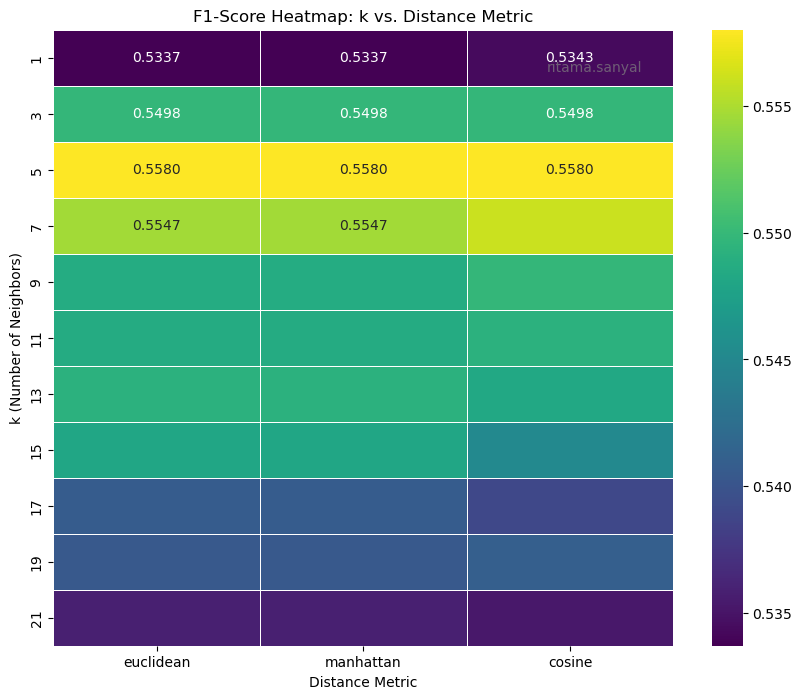

In [8]:
# Call the plotting function to generate the heatmap
predictor.plot_knn_f1_heatmap(f1_scores_df)

Which distance metric performs better? Why might that be?

# Performance of Distance Metrics in k-NN Classification
* The **peak F1-score (0.558)** occurs at `k=5` and is **identical** for Euclidean, Manhattan, and Cosine.
* Slightly lower peaks occur for higher `k`.
* Cosine is **slightly worse** at larger k (e.g., 15–17) compared to Euclidean and Manhattan.
---
### **Step 2: Observations**

1. **Manhattan vs Euclidean:**

   * Scores are identical or very close across all `k`.
   * Indicates the dataset features are probably **numerical, evenly scaled**, and the magnitude difference (Euclidean) vs absolute difference (Manhattan) does not matter much.

2. **Cosine:**

   * Cosine distance performs slightly worse for large `k` values.
   * Cosine measures **angle between vectors**, ignoring magnitude.
   * If absolute feature values matter (e.g., GPA, numerical program encodings), then Euclidean/Manhattan better capture these differences.

---

### **Step 3: Conclusion**

* **Best-performing metric:** **Manhattan or Euclidean** .
* **Reason:**

  * Features are mostly **numerical and on similar scales**, so distance magnitude matters.
  * Cosine distance ignores magnitude and only considers vector orientation, which makes it slightly less effective in capturing the actual similarity for this dataset.

---
**Summary Statement:**

> Manhattan and Euclidean distances perform equally well, achieving the highest F1-score at `k=5`. Cosine distance is slightly worse for larger k, likely because it ignores magnitude differences, which are important in this dataset.
However, Manhattan is more computationlly effective.

 Instead of using all student features, an alternative is to use a single feature for pre
diction. Create an F-1 score table where rows are various values of k, columns are the
 single features used. Report values for test set for all the distance metrics.

In [9]:
# Define the parameters for the experiment
k_values = range(1, 22, 2)
features_to_test = ['GPA', 'major', 'program']
distances = ['euclidean', 'manhattan', 'cosine']

print("--- Calculating F1-Scores on the TEST SET using Single Features ---")

# This will return a dictionary of DataFrames
single_feature_results = predictor.get_knn_f1_single_feature_table(
    k_values,
    features_to_test,
    distances
)

# Display the results table for each distance metric
for distance, df_result in single_feature_results.items():
    print(f"\n--- Results for {distance.capitalize()} Distance ---")
    display(df_result)

--- Calculating F1-Scores on the TEST SET using Single Features ---

--- Results for Euclidean Distance ---


,gpa,major,program
k,,,
1,0.543447,0.513387,0.540444
3,0.554890,0.257181,0.547351
5,0.559451,0.548880,0.547351
7,0.545050,0.513387,0.547351
9,0.550767,0.548880,0.547351
11,0.557262,0.548880,0.411057
13,0.556927,0.257181,0.547351
15,0.542892,0.257181,0.547351
17,0.540409,0.257181,0.411057



--- Results for Manhattan Distance ---


,gpa,major,program
k,,,
1,0.543447,0.513387,0.540444
3,0.554890,0.257181,0.547351
5,0.559451,0.548880,0.547351
7,0.545050,0.513387,0.547351
9,0.550767,0.548880,0.547351
11,0.557262,0.548880,0.411057
13,0.556927,0.257181,0.547351
15,0.542892,0.257181,0.547351
17,0.540409,0.257181,0.411057



--- Results for Cosine Distance ---


,gpa,major,program
k,,,
1,0.500588,0.513387,0.508930
3,0.498837,0.164194,0.508930
5,0.513387,0.513387,0.530008
7,0.513387,0.513387,0.530008
9,0.513387,0.513387,0.530008
11,0.513387,0.513387,0.513387
13,0.513387,0.513387,0.513387
15,0.513387,0.513387,0.513387
17,0.513387,0.513387,0.513387


Which single feature performed the best? How does it compare with the result using
 all the features? Why?

In [10]:
for distance, df_result in single_feature_results.items():
    # Find the max F1-score and corresponding feature and k
    max_f1 = df_result.max().max()
    best_feature = df_result.max().idxmax()
    best_k = df_result[best_feature].idxmax()
    print(f"For {distance.capitalize()} distance: Best feature = '{best_feature}', Best k = {best_k}, Max F1-score = {max_f1:.4f}")

For Euclidean distance: Best feature = 'gpa', Best k = 5, Max F1-score = 0.5595
For Manhattan distance: Best feature = 'gpa', Best k = 5, Max F1-score = 0.5595
For Cosine distance: Best feature = 'program', Best k = 5, Max F1-score = 0.5300


## Analysis of k-NN Classifier Performance

### Best Single Feature

- **Euclidean & Manhattan Distances:**  
  The feature **`gpa`** is the most informative single feature, achieving a maximum F1-score of approximately **0.5595** at **k=5**.

- **Cosine Distance:**  
  The feature **`program`** performs best, but with a lower F1-score of around **0.5300**.

---

### Using All Features

- The highest F1-score using **all features** is about **0.5580** (Euclidean distance, k=5), which is slightly **lower** than using `gpa` alone.

---

### Explanation

- In this dataset, **`gpa`** is highly informative for predicting gender.  
- Adding other features, especially one-hot encoded categorical features, increases **dimensionality** and may introduce **noise**.  
- k-NN is sensitive to **irrelevant or weak features**, and in high-dimensional spaces, distances become less meaningful (curse of dimensionality).  
- As a result, a single strong feature can outperform all features combined if the additional features do not provide useful information.

---

### Summary

- Using **`gpa` alone** gives the best F1-score.  
- Using **all features** does not improve performance and may slightly reduce it due to **added noise** and **high dimensionality**.  